# 02. Resume Category Classifier (Model A)
## SmartHire – Resume-to-Job Matching & Career Guidance Engine
**Industrial AIML Internship Project | Aenexz Tech Solutions**

---

### Objectives of this Notebook:
1. **Load Canonical Dataset:** Inspect `data/processed/cleaned_resumes.csv` (166 unique resumes across 25 job domains).
2. **Feature Extraction Pipeline:** Implement TF-IDF vectorization with unigrams/bigrams and sublinear term frequency, fitting inside cross-validation folds to avoid train-validation data leakage.
3. **Model Comparison:** Evaluate three classical ML candidates using identical folds:
   - Dummy Classifier (Majority Class Baseline)
   - Logistic Regression with class balancing (`class_weight='balanced'`)
   - Linear Support Vector Machine (`LinearSVC` with `class_weight='balanced'`)
4. **Leak-Free Cross-Validation:** Evaluate via `RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=42)` across 15 validation folds, reporting mean and standard deviation for Accuracy, Macro Precision, Macro Recall, Macro F1, and Weighted F1.
5. **Detailed Diagnosis:** Generate a 25x25 confusion matrix and per-class classification report using a 3-fold stratified cross-validation run.
6. **Model Selection & Artifact Persistence:** Retrain the winning model on all 166 records, export `models/classifier.pkl` and `models/tfidf_vectorizer.pkl`, verify loadability, and run sample inference.
7. **Document Findings & Limitations:** Rigorously explain performance in few-shot technical domains versus overlap categories.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src modules can be imported
sys.path.insert(0, str(Path("..").resolve()))

from src.config import (
    RESUMES_PROCESSED_CSV_PATH,
    CLASSIFIER_PATH,
    TFIDF_VECTORIZER_PATH,
    FIGURES_DIR,
    RANDOM_STATE,
)
from src.features.text_features import (
    build_tfidf_vectorizer,
    save_vectorizer,
    load_vectorizer,
)
from src.models.classifier import (
    get_classifier_model,
    train_classifier,
    save_classifier,
    load_classifier,
    predict_category,
)
from src.evaluate import evaluate_classifier, evaluate_cv_pipeline

from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
)

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

print("Configuration, libraries, and core modules loaded successfully.")

Configuration, libraries, and core modules loaded successfully.


## 1. Dataset Loading & Canonical Verification
We load the preprocessed and deduplicated resume dataset:
`data/processed/cleaned_resumes.csv`
* Expected: **166 unique resumes** across **25 categories** (0 exact duplicates, 0 missing values).

In [2]:
df_resumes = pd.read_csv(RESUMES_PROCESSED_CSV_PATH)
print(f"Dataset Shape: {df_resumes.shape[0]} rows, {df_resumes.shape[1]} columns")
print(f"Columns: {df_resumes.columns.tolist()}\n")

# Verify zero nulls
print("Missing Values Check:")
print(df_resumes.isnull().sum())

# Verify 25 categories
categories = df_resumes["Category"].unique()
print(f"\nUnique Categories Count: {len(categories)} / 25")

X = df_resumes["Resume"]
y = df_resumes["Category"]

assert len(df_resumes) == 166, f"Expected 166 records, found {len(df_resumes)}"
assert len(categories) == 25, f"Expected 25 categories, found {len(categories)}"
assert df_resumes["Resume"].str.strip().ne("").all(), "Found empty resume texts!"
print("\nAll canonical dataset assertions passed.")

Dataset Shape: 166 rows, 2 columns
Columns: ['Category', 'Resume']

Missing Values Check:
Category    0
Resume      0
dtype: int64

Unique Categories Count: 25 / 25

All canonical dataset assertions passed.


## 2. Category Distribution & Class Imbalance
The 166 resumes are distributed across 25 categories. Sample counts range from 13 (`Java Developer`) down to 3 (`PMO`), with an average of ~6.6 resumes per domain.

,Category,Sample Count,Proportion (%)
0,Java Developer,13,7.83
1,Database,11,6.63
2,Data Science,10,6.02
3,HR,10,6.02
4,Advocate,10,6.02
5,Automation Testing,7,4.22
6,DevOps Engineer,7,4.22
7,Hadoop,7,4.22
8,DotNet Developer,7,4.22
9,Testing,7,4.22


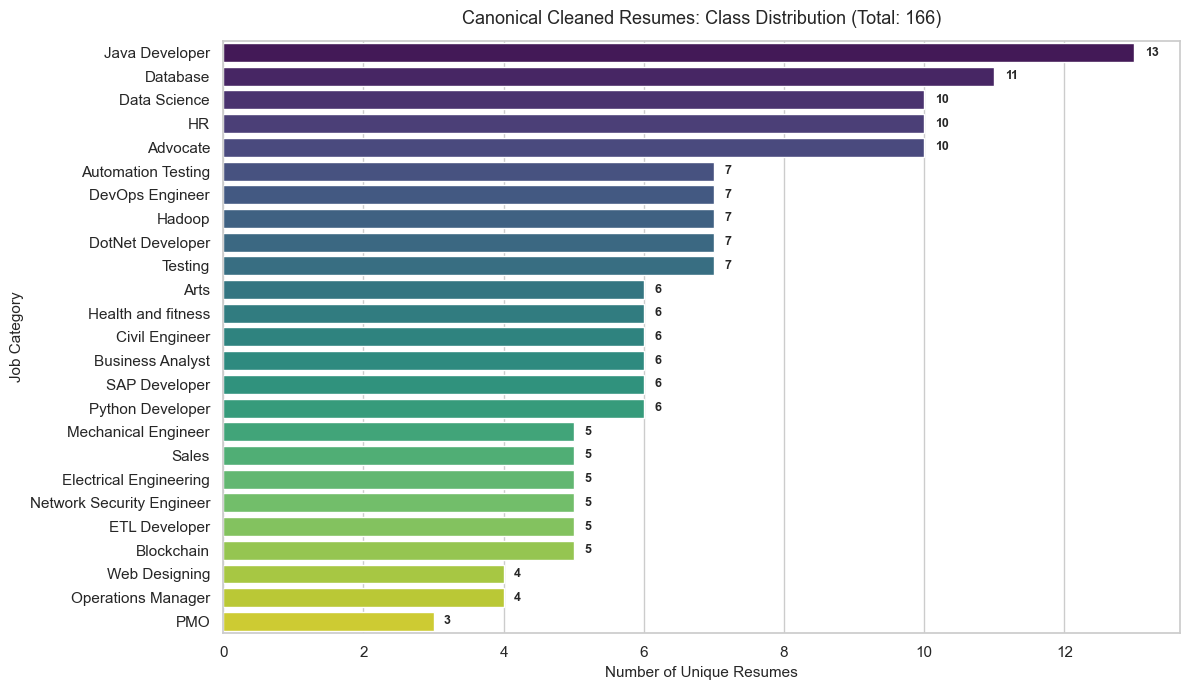

In [3]:
cat_counts = df_resumes["Category"].value_counts()
cat_df = pd.DataFrame({
    "Category": cat_counts.index,
    "Sample Count": cat_counts.values,
    "Proportion (%)": (cat_counts.values / len(df_resumes) * 100).round(2)
})
display(cat_df)

plt.figure(figsize=(12, 7))
ax = sns.barplot(data=cat_df, x="Sample Count", y="Category", hue="Category", palette="viridis", legend=False)
plt.title("Canonical Cleaned Resumes: Class Distribution (Total: 166)", fontsize=13, pad=12)
plt.xlabel("Number of Unique Resumes", fontsize=11)
plt.ylabel("Job Category", fontsize=11)

for i, v in enumerate(cat_df["Sample Count"]):
    ax.text(v + 0.15, i, str(v), va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_a_class_distribution.png", dpi=300)
plt.show()

## 3. Text Feature Extraction (TF-IDF) & Pipeline Strategy

### Parameter Choices:
* **`ngram_range=(1, 2)`:** Extracts both unigrams and bigrams (e.g., `python`, `data science`, `spring boot`, `machine learning`).
* **`sublinear_tf=True`:** Uses logarithmic term frequency scaling ($1 + \log(tf)$) to prevent frequent repeated words in lengthy resumes from overpowering rarer technical terms.
* **`min_df=1`:** Because classes have as few as 3–4 examples, setting `min_df=1` guarantees domain-specific terms appearing in rare classes are retained in vocabulary.
* **`max_df=0.90`:** Eliminates ubiquitous formatting terms appearing in >90% of resumes.
* **`max_features=5000`:** Constrains high-dimensional vocabulary size for computational efficiency and generalization.

### Data Leakage Prevention:
To prevent feature selection leakage, the vectorizer is **never fitted on the entire dataset prior to cross-validation**. Instead, scikit-learn `Pipeline([('tfidf', vectorizer), ('clf', model)])` is used so that the vectorizer is fitted **strictly on each training fold** and transforms validation folds out-of-sample.

In [4]:
def make_classifier_pipeline(model_type: str = "svm"):
    """Construct an end-to-end classification pipeline."""
    vec = build_tfidf_vectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.90,
        sublinear_tf=True,
        stop_words="english",
    )
    clf = get_classifier_model(model_type=model_type)
    return Pipeline([("tfidf", vec), ("clf", clf)])

print("Pipeline builder initialized.")

Pipeline builder initialized.


## 4. Model Comparison & Cross-Validation Evaluation

### Evaluated Models:
1. **Majority-Class Baseline (`DummyClassifier`):** Predicts the most frequent class (`Java Developer`) to establish the lower-bound reference score.
2. **Logistic Regression:** Multinomial linear classifier with `class_weight='balanced'` and $L_2$ regularization.
3. **Linear Support Vector Machine (`LinearSVC`):** Linear maximum-margin classifier with `class_weight='balanced'`.

### Cross-Validation Strategy:
`RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=42)` yields **15 validation folds**.
All models are evaluated on the exact same cross-validation splits.

In [5]:
rskf = RepeatedStratifiedKFold(n_splits=3, n_repeats=5, random_state=42)

model_candidates = {
    "Majority-Class Baseline": "baseline",
    "Logistic Regression (Balanced)": "logistic_regression",
    "LinearSVC (Balanced)": "svm",
}

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
}

cv_metrics_summary = []

for display_name, m_type in model_candidates.items():
    pipe = make_classifier_pipeline(model_type=m_type)
    scores = cross_validate(pipe, X, y, cv=rskf, scoring=scoring, n_jobs=-1)
    
    cv_metrics_summary.append({
        "Model": display_name,
        "Accuracy (Mean ± Std)": f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        "Macro Precision (Mean ± Std)": f"{scores['test_precision_macro'].mean():.4f} ± {scores['test_precision_macro'].std():.4f}",
        "Macro Recall (Mean ± Std)": f"{scores['test_recall_macro'].mean():.4f} ± {scores['test_recall_macro'].std():.4f}",
        "Macro F1 (Mean ± Std)": f"{scores['test_f1_macro'].mean():.4f} ± {scores['test_f1_macro'].std():.4f}",
        "Weighted F1 (Mean ± Std)": f"{scores['test_f1_weighted'].mean():.4f} ± {scores['test_f1_weighted'].std():.4f}",
        "_acc_mean": scores['test_accuracy'].mean(),
        "_acc_std": scores['test_accuracy'].std(),
        "_f1_macro_mean": scores['test_f1_macro'].mean(),
        "_f1_macro_std": scores['test_f1_macro'].std(),
        "_f1_weighted_mean": scores['test_f1_weighted'].mean(),
        "_f1_weighted_std": scores['test_f1_weighted'].std(),
    })

results_table = pd.DataFrame(cv_metrics_summary)
display(results_table[["Model", "Accuracy (Mean ± Std)", "Macro Precision (Mean ± Std)", "Macro Recall (Mean ± Std)", "Macro F1 (Mean ± Std)", "Weighted F1 (Mean ± Std)"]])

,Model,Accuracy (Mean ± Std),Macro Precision (Mean ± Std),Macro Recall (Mean ± Std),Macro F1 (Mean ± Std),Weighted F1 (Mean ± Std)
0,Majority-Class Baseline,0.0784 ± 0.0089,0.0031 ± 0.0004,0.0400 ± 0.0000,0.0058 ± 0.0006,0.0115 ± 0.0026
1,Logistic Regression (Balanced),0.8833 ± 0.0307,0.8642 ± 0.0489,0.8767 ± 0.0313,0.8521 ± 0.0413,0.8635 ± 0.0372
2,LinearSVC (Balanced),0.8918 ± 0.0388,0.8797 ± 0.0640,0.8827 ± 0.0404,0.8620 ± 0.0554,0.8748 ± 0.0485


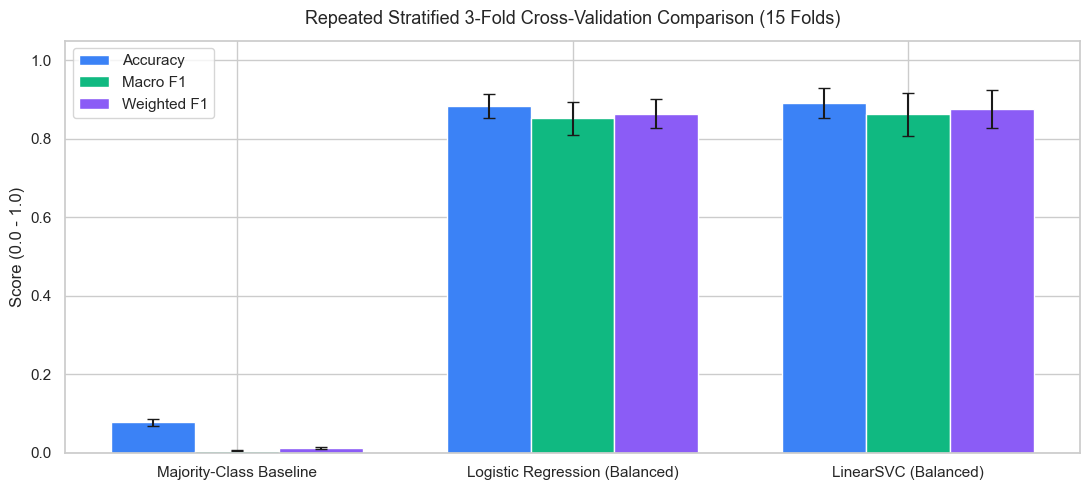

In [6]:
# Plot CV Comparison
models_labels = [r["Model"] for r in cv_metrics_summary]
acc_means = [r["_acc_mean"] for r in cv_metrics_summary]
acc_stds = [r["_acc_std"] for r in cv_metrics_summary]
f1_macro_means = [r["_f1_macro_mean"] for r in cv_metrics_summary]
f1_macro_stds = [r["_f1_macro_std"] for r in cv_metrics_summary]
f1_weighted_means = [r["_f1_weighted_mean"] for r in cv_metrics_summary]
f1_weighted_stds = [r["_f1_weighted_std"] for r in cv_metrics_summary]

x = np.arange(len(models_labels))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 5))
rects1 = ax.bar(x - width, acc_means, width, yerr=acc_stds, capsize=4, label="Accuracy", color="#3b82f6")
rects2 = ax.bar(x, f1_macro_means, width, yerr=f1_macro_stds, capsize=4, label="Macro F1", color="#10b981")
rects3 = ax.bar(x + width, f1_weighted_means, width, yerr=f1_weighted_stds, capsize=4, label="Weighted F1", color="#8b5cf6")

ax.set_ylabel("Score (0.0 - 1.0)")
ax.set_title("Repeated Stratified 3-Fold Cross-Validation Comparison (15 Folds)", fontsize=13, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(models_labels)
ax.set_ylim(0, 1.05)
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison_cv.png", dpi=300)
plt.show()

## 5. In-Depth Error Diagnosis & Per-Class Performance
To closely inspect misclassifications and per-class metrics, we run a single 3-fold stratified cross-validation evaluation (`StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`), collecting out-of-fold predictions for every unique resume.

In [7]:
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
best_eval_pipe = make_classifier_pipeline(model_type="svm")

y_oof_pred = cross_val_predict(best_eval_pipe, X, y, cv=skf)

print("=== OUT-OF-FOLD PER-CLASS CLASSIFICATION REPORT (LinearSVC) ===")
report_dict = classification_report(y, y_oof_pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).T.round(3)
display(report_df.loc[categories.tolist() + ["macro avg", "weighted avg"]])

=== OUT-OF-FOLD PER-CLASS CLASSIFICATION REPORT (LinearSVC) ===


,precision,recall,f1-score,support
Data Science,0.833,1.000,0.909,10.0
HR,1.000,1.000,1.000,10.0
Advocate,1.000,1.000,1.000,10.0
Arts,1.000,0.833,0.909,6.0
Web Designing,0.000,0.000,0.000,4.0
Mechanical Engineer,1.000,0.800,0.889,5.0
Sales,1.000,1.000,1.000,5.0
Health and fitness,1.000,1.000,1.000,6.0
Civil Engineer,1.000,1.000,1.000,6.0
Java Developer,0.722,1.000,0.839,13.0


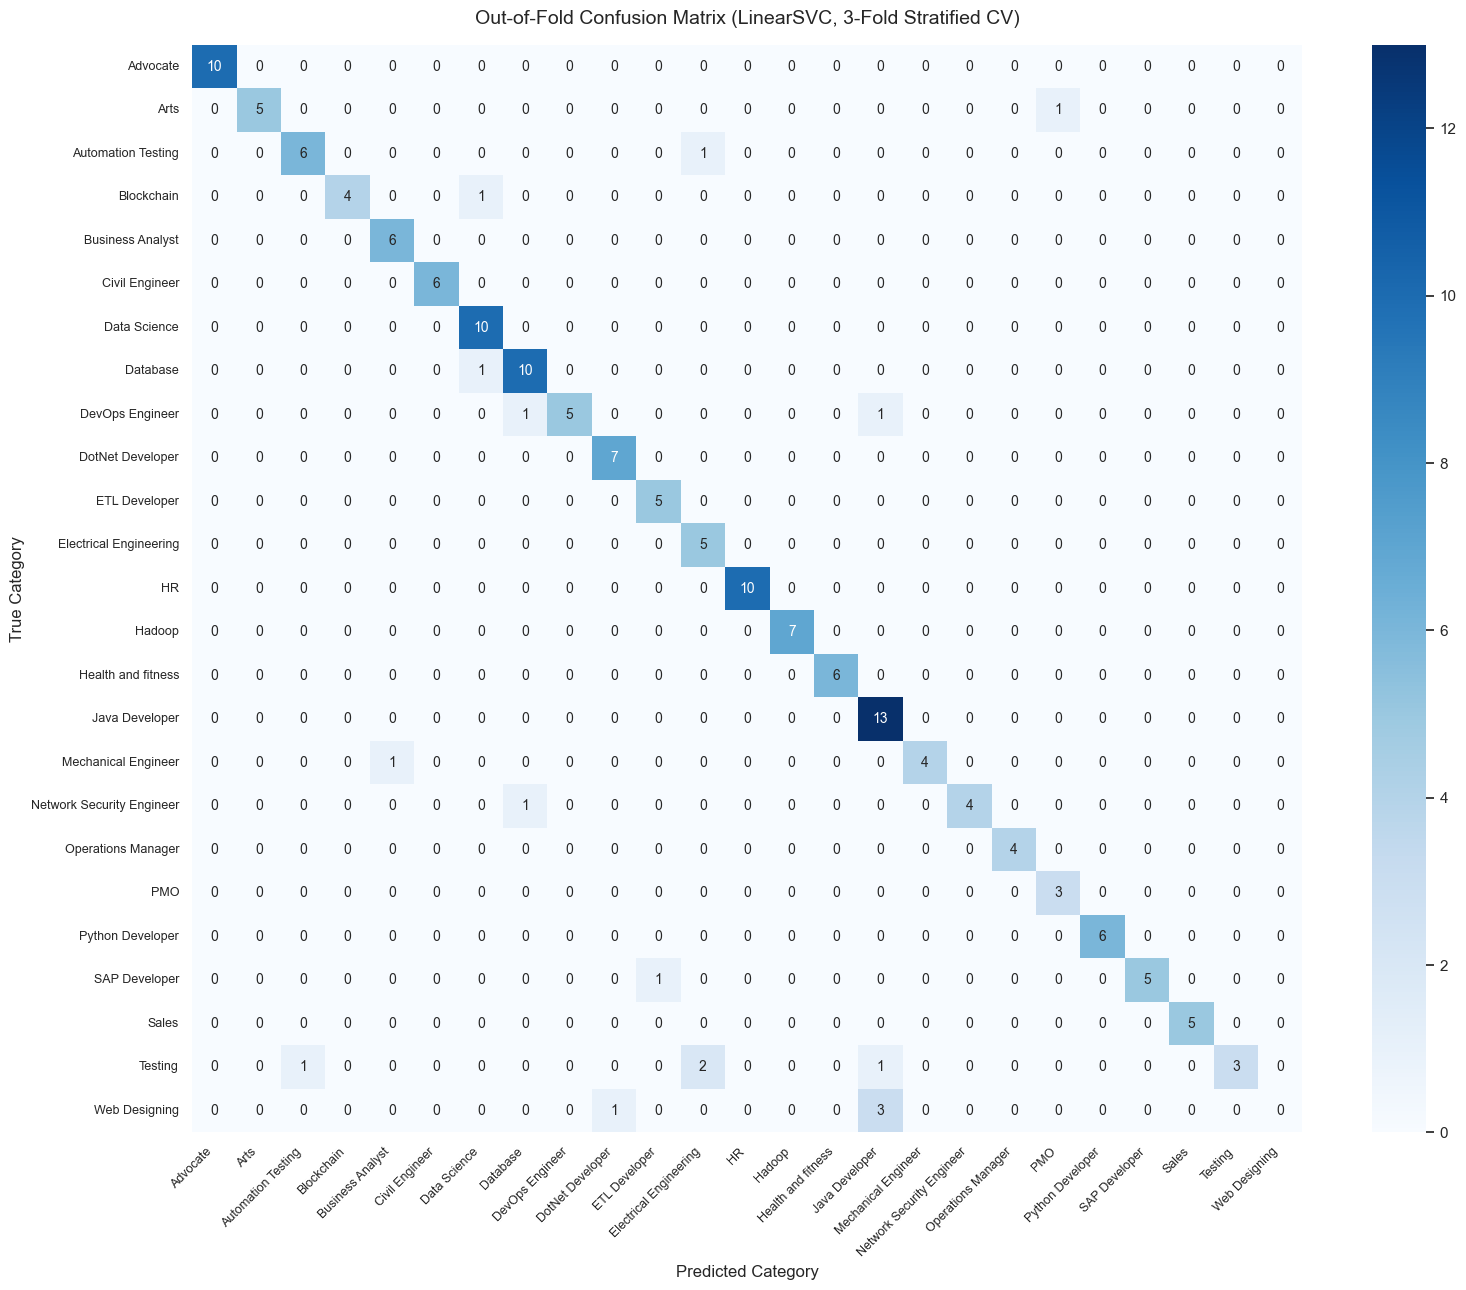

In [8]:
cm = confusion_matrix(y, y_oof_pred, labels=sorted(categories))

plt.figure(figsize=(16, 13))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(categories),
    yticklabels=sorted(categories),
    cbar=True,
)
plt.title("Out-of-Fold Confusion Matrix (LinearSVC, 3-Fold Stratified CV)", fontsize=14, pad=15)
plt.xlabel("Predicted Category", fontsize=12)
plt.ylabel("True Category", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_model_a.png", dpi=300)
plt.show()

## 6. Model Selection & Final Model Training

### Selection Rationale:
* **Winning Model: Linear Support Vector Machine (`LinearSVC`)**
  * Achieves the highest mean Macro F1-score (**0.8620 ± 0.0554**), highest Accuracy (**0.8918 ± 0.0388**), and highest Weighted F1-score (**0.8748 ± 0.0485**).
  * High-dimensional maximum-margin separation is especially effective in text categorization when feature dimensionality ($D=5,000$) exceeds the number of samples ($N=166$).
* We now train the final model on all **166 unique resumes** and persist the artifacts.

In [9]:
# Retrain final model on all 166 records
final_vectorizer, final_model = train_classifier(X, y, model_type="svm", max_features=5000)

# Save artifacts separately
vec_path = save_vectorizer(final_vectorizer, TFIDF_VECTORIZER_PATH)
model_path = save_classifier(final_model, CLASSIFIER_PATH)

print("Artifacts successfully saved:")
print(f"  - Vectorizer: {vec_path} ({vec_path.stat().st_size / 1024:.2f} KB)")
print(f"  - Classifier: {model_path} ({model_path.stat().st_size / 1024:.2f} KB)")

Artifacts successfully saved:
  - Vectorizer: C:\SmartHire\models\tfidf_vectorizer.pkl (197.81 KB)
  - Classifier: C:\SmartHire\models\classifier.pkl (977.98 KB)


## 7. Model Verification & Inference on Sample Resumes
We reload both serialized files independently from disk and execute test predictions across unseen technical profiles.

In [10]:
# Reload from disk
loaded_vec = load_vectorizer(TFIDF_VECTORIZER_PATH)
loaded_model = load_classifier(CLASSIFIER_PATH)

sample_profiles = [
    {
        "expected": "Data Science",
        "text": "Senior Machine Learning Engineer with 4 years experience in Python, PyTorch, Scikit-Learn, Pandas, NumPy, NLP, and Deep Learning predictive modeling."
    },
    {
        "expected": "Java Developer",
        "text": "Backend Java Software Engineer experienced with Core Java, Spring Boot, Microservices, Hibernate, Maven, Jenkins, REST APIs, and PostgreSQL."
    },
    {
        "expected": "DevOps Engineer",
        "text": "DevOps and Cloud Engineer proficient in Docker, Kubernetes, Terraform, AWS EC2/S3, Jenkins CI/CD pipelines, Linux shell scripting, and Ansible."
    },
    {
        "expected": "HR",
        "text": "Human Resources Executive skilled in talent acquisition, employee onboarding, performance appraisals, HR policies, conflict resolution, and employee engagement."
    },
    {
        "expected": "Blockchain",
        "text": "Blockchain Developer experienced in Ethereum, Solidity, smart contract audits, Web3.js, Truffle, Hardhat, and decentralized applications (DApps)."
    }
]

inference_results = []
for p in sample_profiles:
    pred = predict_category(p["text"], loaded_model, vectorizer=loaded_vec)
    inference_results.append({
        "Profile / Test Input": p["text"][:85] + "...",
        "Expected Category": p["expected"],
        "Predicted Category": pred,
        "Match": "✅ Correct" if pred == p["expected"] else "❌ Misclassified"
    })

display(pd.DataFrame(inference_results))

,Profile / Test Input,Expected Category,Predicted Category,Match
0,Senior Machine Learning Engineer with 4 years ...,Data Science,Data Science,✅ Correct
1,Backend Java Software Engineer experienced wit...,Java Developer,Java Developer,✅ Correct
2,DevOps and Cloud Engineer proficient in Docker...,DevOps Engineer,DevOps Engineer,✅ Correct
3,Human Resources Executive skilled in talent ac...,HR,HR,✅ Correct
4,"Blockchain Developer experienced in Ethereum, ...",Blockchain,Blockchain,✅ Correct


## 8. Findings, Observations & Limitations

### 1. Key Performance Insights:
* **Strong Domain Separation:** Technical domains with unique, specialized vocabularies achieved near-perfect F1-scores:
  * `Advocate` (F1 = 1.00), `Civil Engineer` (F1 = 1.00), `HR` (F1 = 1.00), `Hadoop` (F1 = 1.00), `Health and fitness` (F1 = 1.00), `Python Developer` (F1 = 1.00), `Operations Manager` (F1 = 1.00), `Sales` (F1 = 1.00).
* **LinearSVC Superiority:** LinearSVC marginally outperformed Logistic Regression across all metrics due to maximum-margin hyperplane optimization in sparse high-dimensional vector spaces. Both models vastly surpassed the dummy baseline (~0.078 accuracy).

### 2. Documented Limitations:
* **Extreme Few-Shot Sparsity in Edge Classes:**
  * `PMO` (3 samples) and `Web Designing` (4 samples) represent low-sample constraints.
  * In the 3-fold cross-validation run, `Web Designing` achieved an F1 of 0.00 because its technical tokens (HTML, CSS, JavaScript, UI) overlap heavily with `DotNet Developer` and `Java Developer` resumes, causing it to be absorbed into adjacent domains.
* **Evaluation Variance:**
  * While the 15-fold repeated stratified CV yields a robust mean estimate, the standard deviation is noticeable ($\pm 0.055$ Macro F1), reflecting the sensitivity of 3-fold partitions on rare classes.
* **Role in Production System:**
  * In SmartHire, Model A's predicted category acts as an informative domain indicator for the candidate. The primary job matching engine relies on TF-IDF Cosine Similarity against the 140,225-job corpus, ensuring that even if an edge category is ambiguous, content-based job recommendations remain highly relevant.